In [2]:
from google.colab import files
uploaded = files.upload()   # choose corn_data.csv and train.csv

Saving corn_data.csv to corn_data.csv
Saving test.csv to test (1).csv
Saving train.csv to train (1).csv


In [3]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, f1_score)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ----------------------------- CONFIG ---------------------------------
REG_CSV = "corn_data.csv"
REG_TARGET = "Yield"
DROP_COLS = ["Farmer"]            # ID column, not a real feature

CLS_CSV = "train (1).csv"
CLS_TARGET = "price_range"

OUT_DIR = "results"
NEURONS = 64        # neurons in every hidden layer
MAX_ITER = 300      # epochs
SEED = 42

# baseline: the other two parameters stay at these values while one is varied
BASE = {"layers": 2, "activation": "relu", "lr": 0.001}

LAYER_OPTIONS = [1, 2, 3, 4]
ACTIVATIONS = ["relu", "tanh", "logistic"]
LEARNING_RATES = [0.0001, 0.001, 0.01, 0.1]
# -----------------------------------------------------------------------

os.makedirs(OUT_DIR, exist_ok=True)


def load_data(path, target):
    df = pd.read_csv(path)
    df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
    df = df.dropna(subset=[target])
    y = df[target]
    X = df.drop(columns=[target])
    # fill missing values instead of deleting rows
    for c in X.columns:
        if X[c].dtype == object or str(X[c].dtype).startswith("str"):
            X[c] = X[c].fillna(X[c].mode().iloc[0])
        else:
            X[c] = X[c].fillna(X[c].median())
    X = pd.get_dummies(X, drop_first=True)   # text columns -> numbers
    return X.values.astype(float), y.values


def prepare(task, path, target):
    X, y = load_data(path, target)
    strat = y if task == "classification" else None
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=strat)
    sx = StandardScaler().fit(Xtr)
    Xtr, Xte = sx.transform(Xtr), sx.transform(Xte)
    sy = None
    if task == "regression":
        sy = StandardScaler().fit(ytr.reshape(-1, 1))
        ytr_s = sy.transform(ytr.reshape(-1, 1)).ravel()
    else:
        ytr_s = ytr
    return Xtr, Xte, ytr, yte, ytr_s, sy


def run_one(task, data, layers, activation, lr):
    Xtr, Xte, ytr, yte, ytr_s, sy = data
    kwargs = dict(hidden_layer_sizes=(NEURONS,) * layers, activation=activation,
                  learning_rate_init=lr, max_iter=MAX_ITER, solver="adam",
                  random_state=SEED)
    model = MLPRegressor(**kwargs) if task == "regression" else MLPClassifier(**kwargs)
    t0 = time.perf_counter()
    model.fit(Xtr, ytr_s)
    elapsed = time.perf_counter() - t0

    if task == "regression":
        ptr = sy.inverse_transform(model.predict(Xtr).reshape(-1, 1)).ravel()
        pte = sy.inverse_transform(model.predict(Xte).reshape(-1, 1)).ravel()
        res = dict(train_error=np.sqrt(mean_squared_error(ytr, ptr)),   # RMSE
                   test_error=np.sqrt(mean_squared_error(yte, pte)),
                   test_mae=mean_absolute_error(yte, pte),
                   test_r2=r2_score(yte, pte))
    else:
        ptr, pte = model.predict(Xtr), model.predict(Xte)
        res = dict(train_error=1 - accuracy_score(ytr, ptr),            # error rate
                   test_error=1 - accuracy_score(yte, pte),
                   test_accuracy=accuracy_score(yte, pte),
                   test_f1=f1_score(yte, pte, average="weighted"))
    res["time_s"] = elapsed
    res["loss_curve"] = model.loss_curve_
    return res


def experiment(task, data, name, values, make_cfg):
    rows, curves = [], {}
    for v in values:
        cfg = make_cfg(v)
        r = run_one(task, data, cfg["layers"], cfg["activation"], cfg["lr"])
        curves[v] = r.pop("loss_curve")
        r.update({"experiment": name, "value": v})
        rows.append(r)
        print(f"[{task}] {name}={v}: train_err={r['train_error']:.4f} "
              f"test_err={r['test_error']:.4f} time={r['time_s']:.1f}s")
    return pd.DataFrame(rows), curves


def plot_experiment(task, name, df, curves):
    err_label = "RMSE" if task == "regression" else "Error rate (1 - accuracy)"
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

    for v, c in curves.items():                      # (a) training loss curves
        ax[0].plot(c, label=str(v))
    ax[0].set_title("Training loss vs epoch")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
    if task == "regression" or name == "learning_rate":
        ax[0].set_yscale("log")
    ax[0].legend(title=name)

    x = np.arange(len(df)); w = 0.38                 # (b) final train/test error
    ax[1].bar(x - w / 2, df["train_error"], w, label="Train")
    ax[1].bar(x + w / 2, df["test_error"], w, label="Test")
    ax[1].set_xticks(x); ax[1].set_xticklabels(df["value"].astype(str))
    ax[1].set_title(f"{err_label} vs {name}")
    ax[1].set_xlabel(name); ax[1].set_ylabel(err_label); ax[1].legend()

    ax[2].bar(x, df["time_s"], color="tab:green")    # (c) training time
    ax[2].set_xticks(x); ax[2].set_xticklabels(df["value"].astype(str))
    ax[2].set_title(f"Training time vs {name}")
    ax[2].set_xlabel(name); ax[2].set_ylabel("Seconds")

    fig.suptitle(f"{task.capitalize()} ANN: effect of {name}")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"{task}_{name}.png"), dpi=150)
    plt.close(fig)


def heatmap(task, data):
    """Activation x learning rate grid of test error."""
    grid = np.zeros((len(ACTIVATIONS), len(LEARNING_RATES)))
    for i, a in enumerate(ACTIVATIONS):
        for j, lr in enumerate(LEARNING_RATES):
            r = run_one(task, data, BASE["layers"], a, lr)
            grid[i, j] = r["test_error"]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    im = ax.imshow(grid, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(LEARNING_RATES))); ax.set_xticklabels(LEARNING_RATES)
    ax.set_yticks(range(len(ACTIVATIONS))); ax.set_yticklabels(ACTIVATIONS)
    ax.set_xlabel("Learning rate"); ax.set_ylabel("Activation")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center", color="w")
    ax.set_title(f"{task.capitalize()}: test error (activation x lr)")
    fig.colorbar(im); fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"{task}_heatmap_activation_lr.png"), dpi=150)
    plt.close(fig)


def run_task(task, path, target):
    print(f"\n===== {task.upper()} : {path} =====")
    data = prepare(task, path, target)
    all_results = []
    specs = [
        ("hidden_layers", LAYER_OPTIONS, lambda v: {**BASE, "layers": v}),
        ("activation", ACTIVATIONS, lambda v: {**BASE, "activation": v}),
        ("learning_rate", LEARNING_RATES, lambda v: {**BASE, "lr": v}),
    ]
    for name, values, mk in specs:
        df, curves = experiment(task, data, name, values, mk)
        plot_experiment(task, name, df, curves)
        all_results.append(df)
    heatmap(task, data)
    out = pd.concat(all_results, ignore_index=True)
    out.to_csv(os.path.join(OUT_DIR, f"{task}_results.csv"), index=False)
    return out


reg = run_task("regression", REG_CSV, REG_TARGET)
cls = run_task("classification", CLS_CSV, CLS_TARGET)

# Regression vs classification: relative test error (value / best in experiment)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ["hidden_layers", "activation", "learning_rate"]):
    for label, res in [("Regression (RMSE)", reg), ("Classification (error rate)", cls)]:
        d = res[res.experiment == name]
        ax.plot(d["value"].astype(str), d["test_error"] / d["test_error"].min(),
                marker="o", label=label)
    ax.set_title(name); ax.set_ylabel("Test error / best test error")
    ax.set_xlabel(name); ax.legend()
fig.suptitle("Regression vs classification: relative sensitivity to each parameter")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "comparison_regression_vs_classification.png"), dpi=150)
plt.close(fig)
print("\nDone. Plots and CSVs are in:", OUT_DIR)


===== REGRESSION : corn_data.csv =====
[regression] hidden_layers=1: train_err=24.2655 test_err=73.6309 time=0.3s
[regression] hidden_layers=2: train_err=14.9472 test_err=75.8345 time=0.6s
[regression] hidden_layers=3: train_err=7.8943 test_err=74.7594 time=1.3s
[regression] hidden_layers=4: train_err=7.2148 test_err=77.2155 time=2.8s
[regression] activation=relu: train_err=14.9472 test_err=75.8345 time=0.5s
[regression] activation=tanh: train_err=15.4528 test_err=59.7373 time=1.4s
[regression] activation=logistic: train_err=44.2214 test_err=48.6813 time=1.1s
[regression] learning_rate=0.0001: train_err=56.7212 test_err=77.5697 time=0.9s
[regression] learning_rate=0.001: train_err=14.9472 test_err=75.8345 time=0.6s
[regression] learning_rate=0.01: train_err=7.3754 test_err=61.9473 time=0.3s
[regression] learning_rate=0.1: train_err=130.9884 test_err=137.2768 time=0.1s

===== CLASSIFICATION : train (1).csv =====
[classification] hidden_layers=1: train_err=0.0000 test_err=0.0725 time=1.

results/classification_activation.png


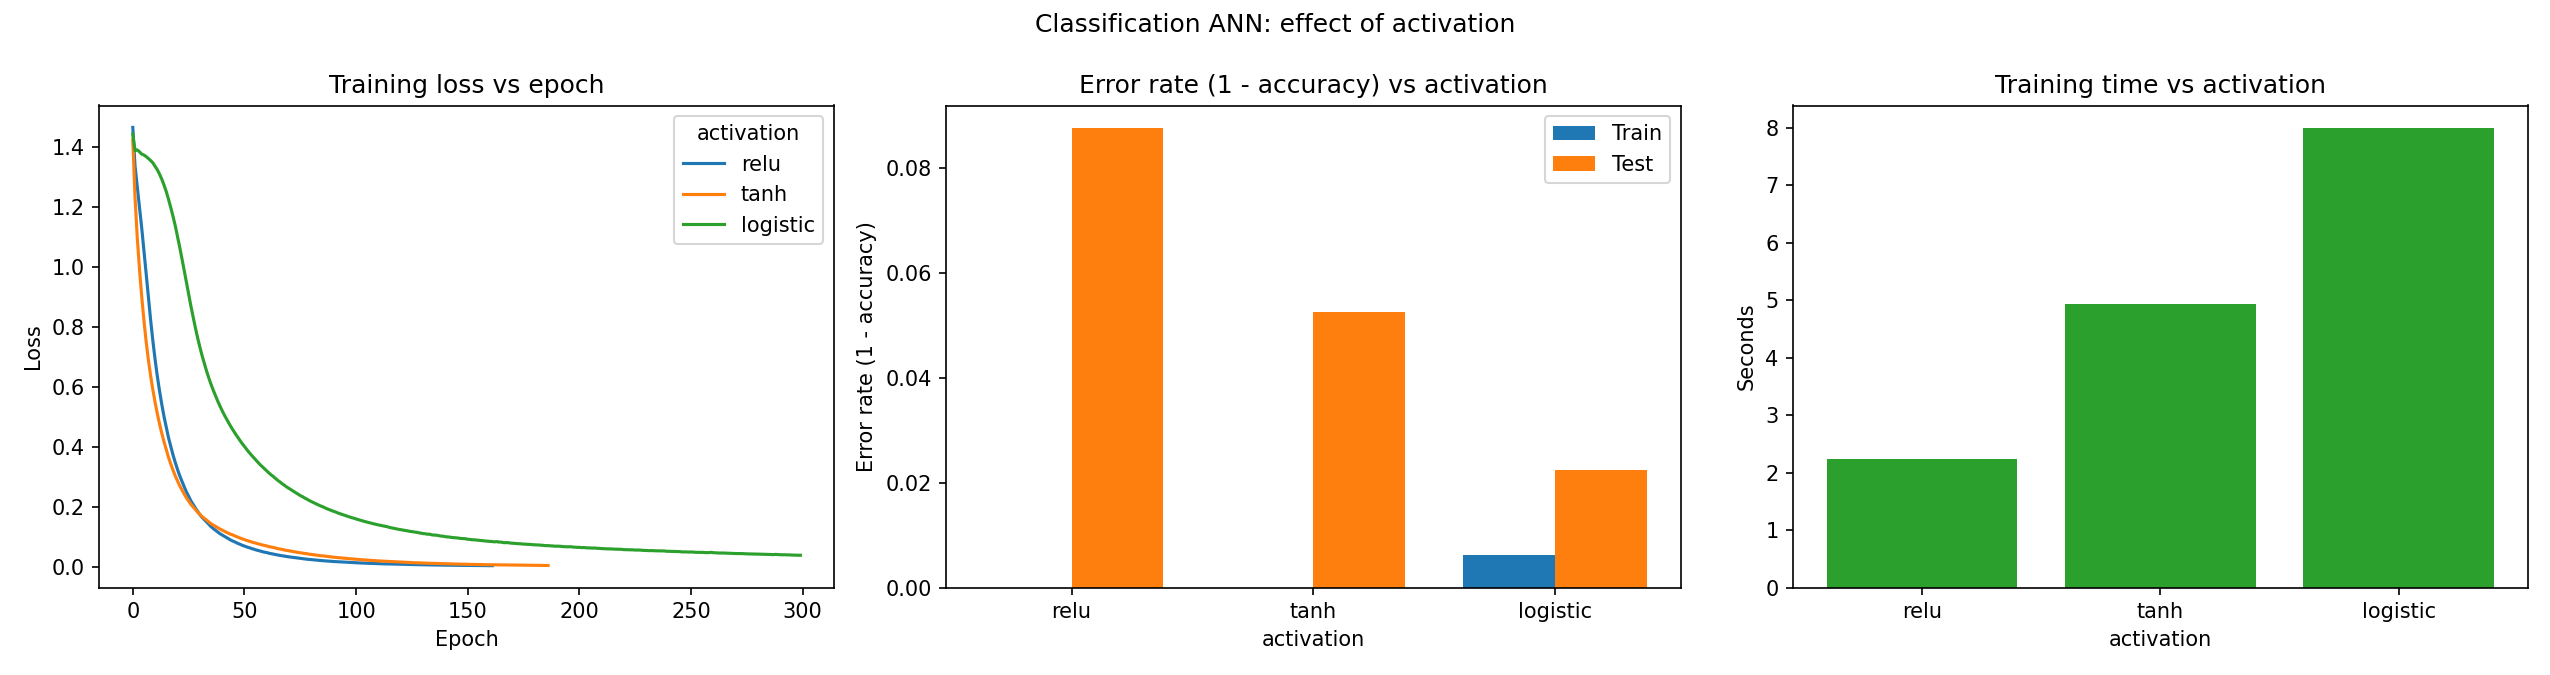

results/classification_heatmap_activation_lr.png


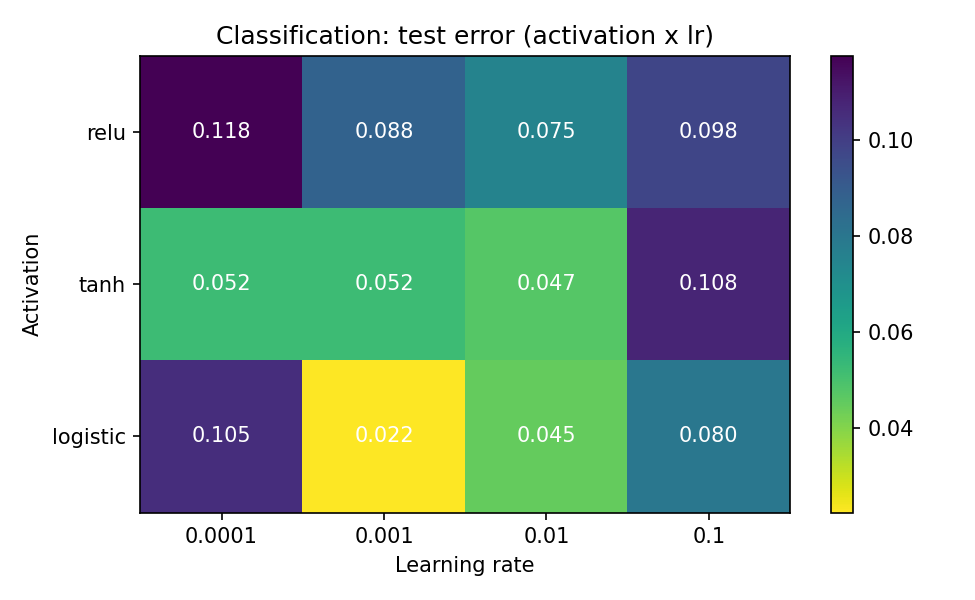

results/classification_hidden_layers.png


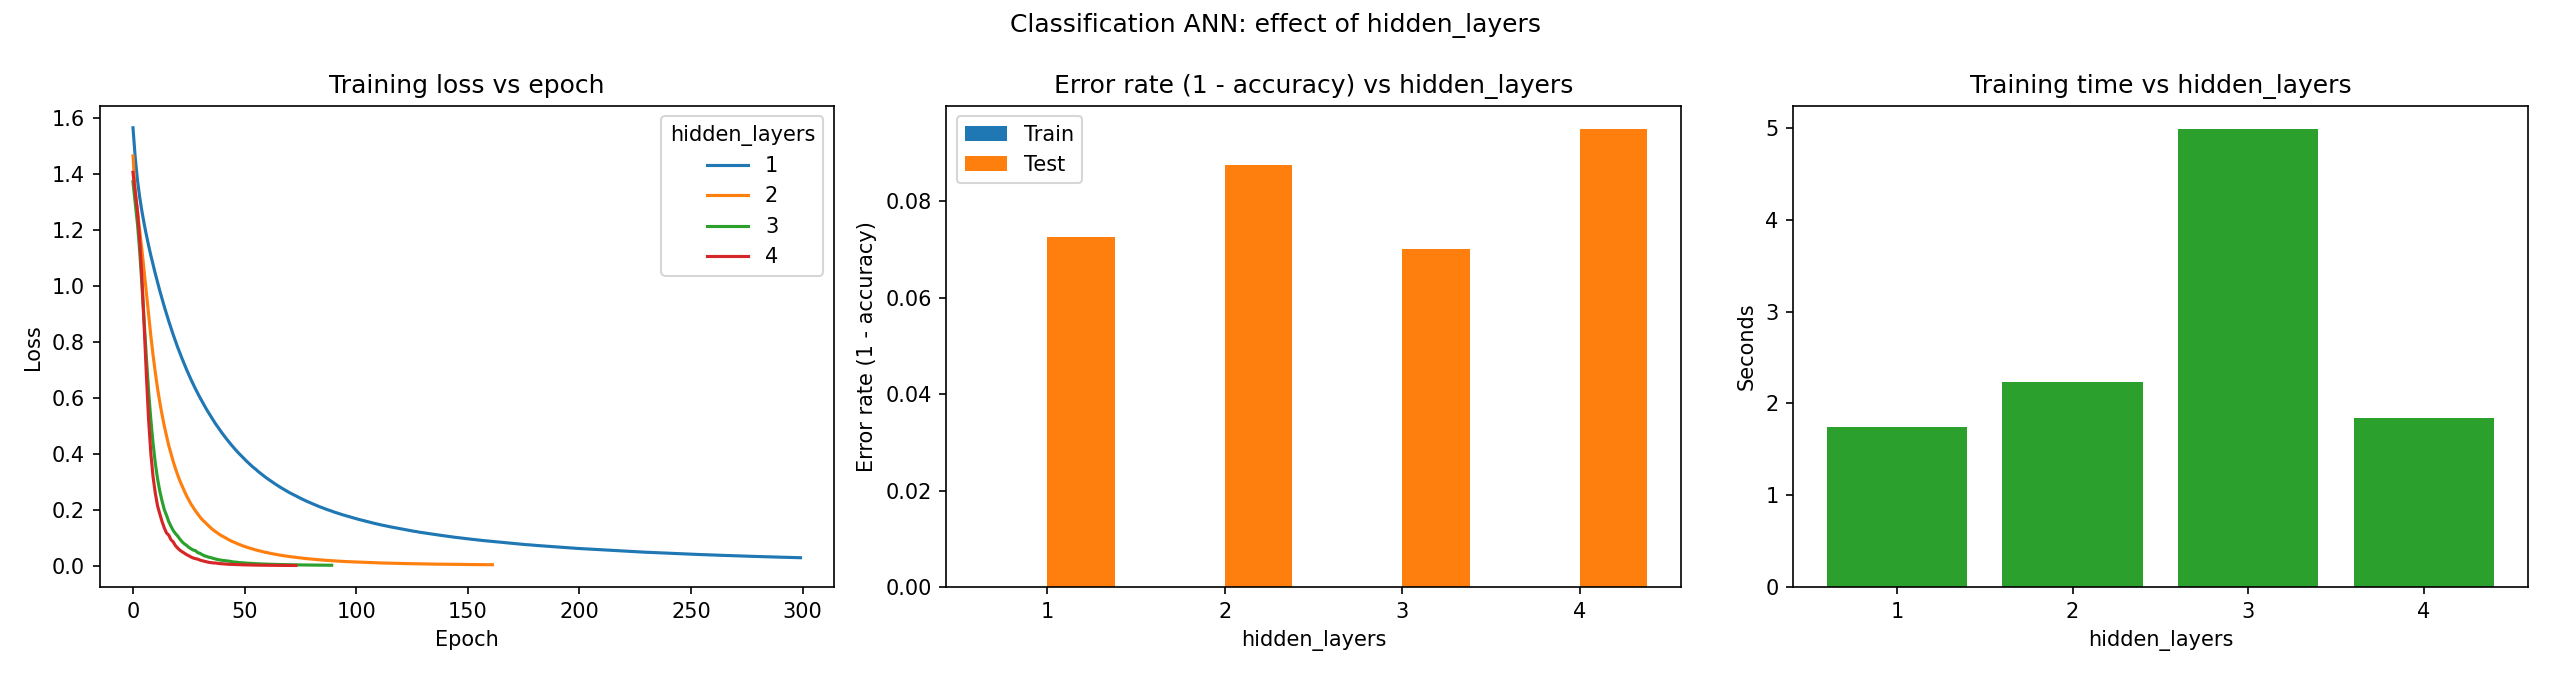

results/classification_learning_rate.png


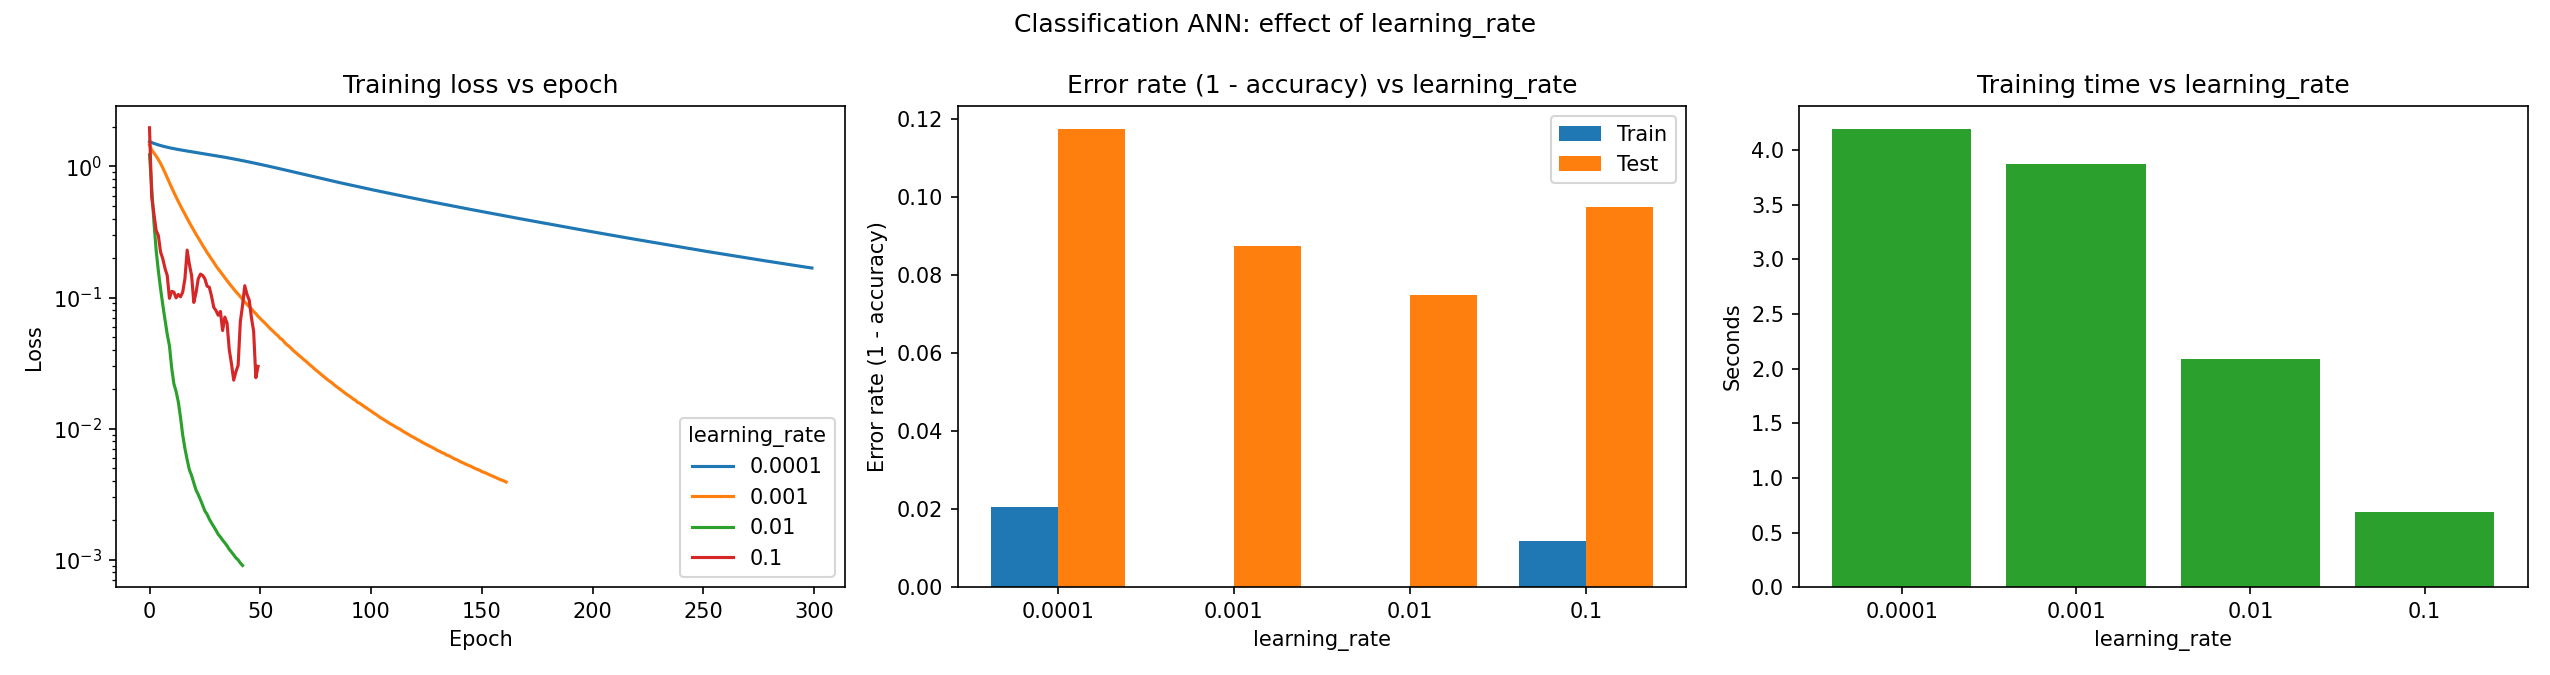

results/comparison_regression_vs_classification.png


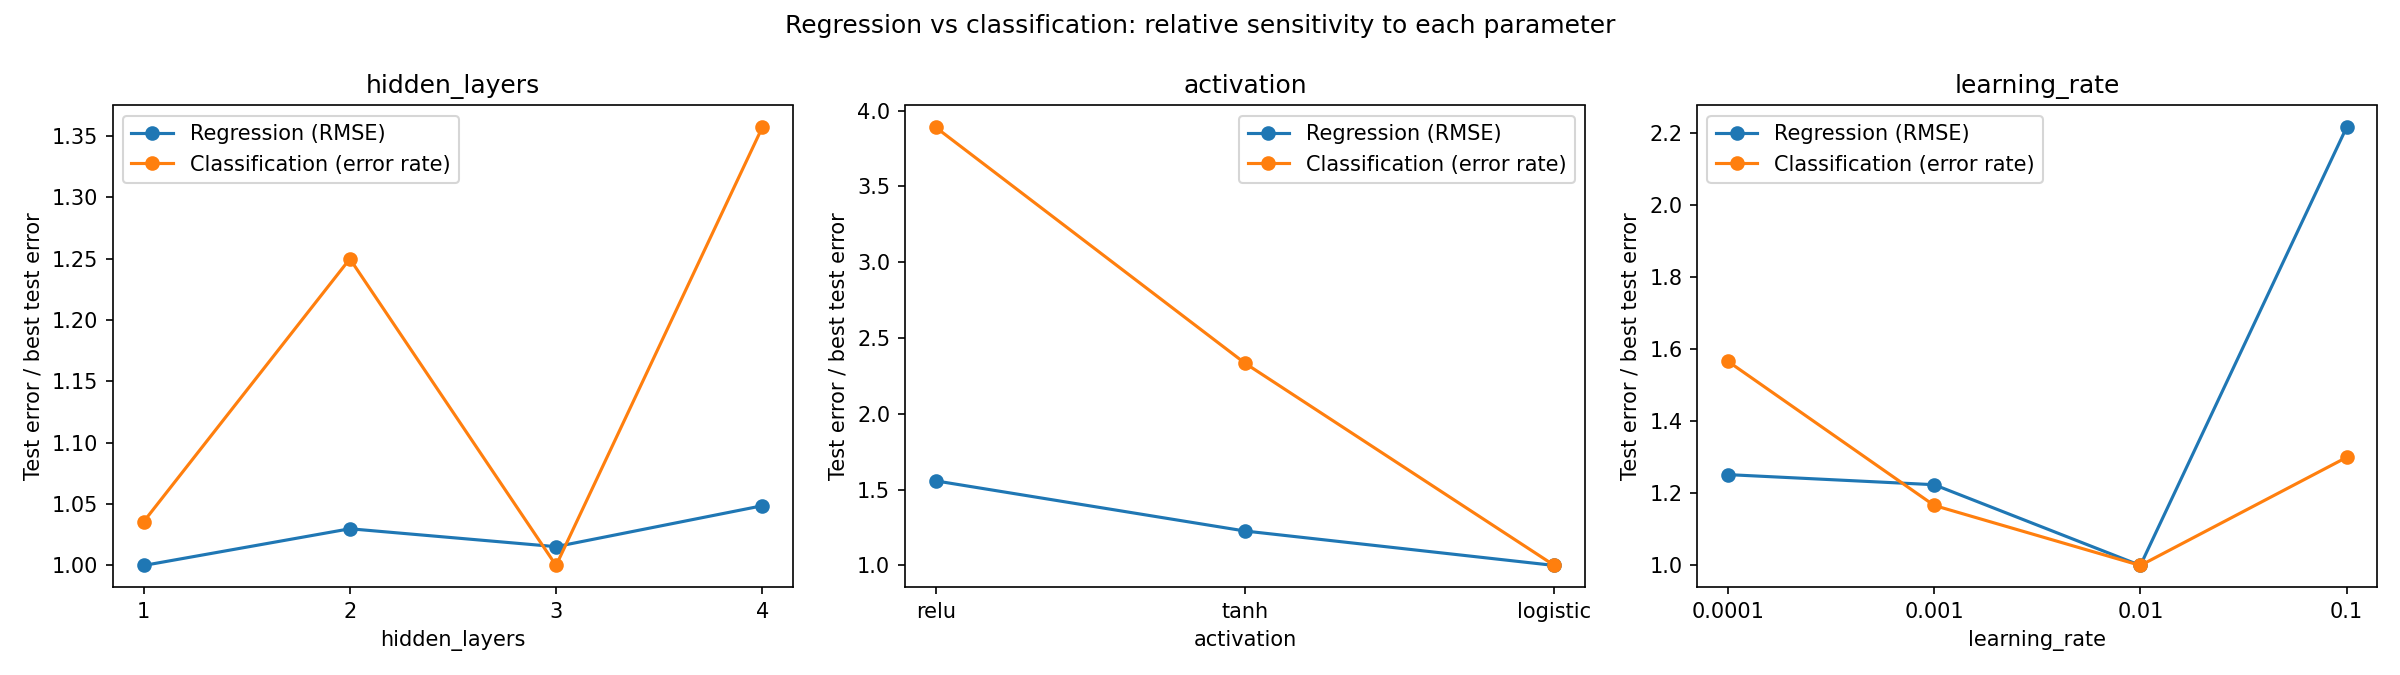

results/regression_activation.png


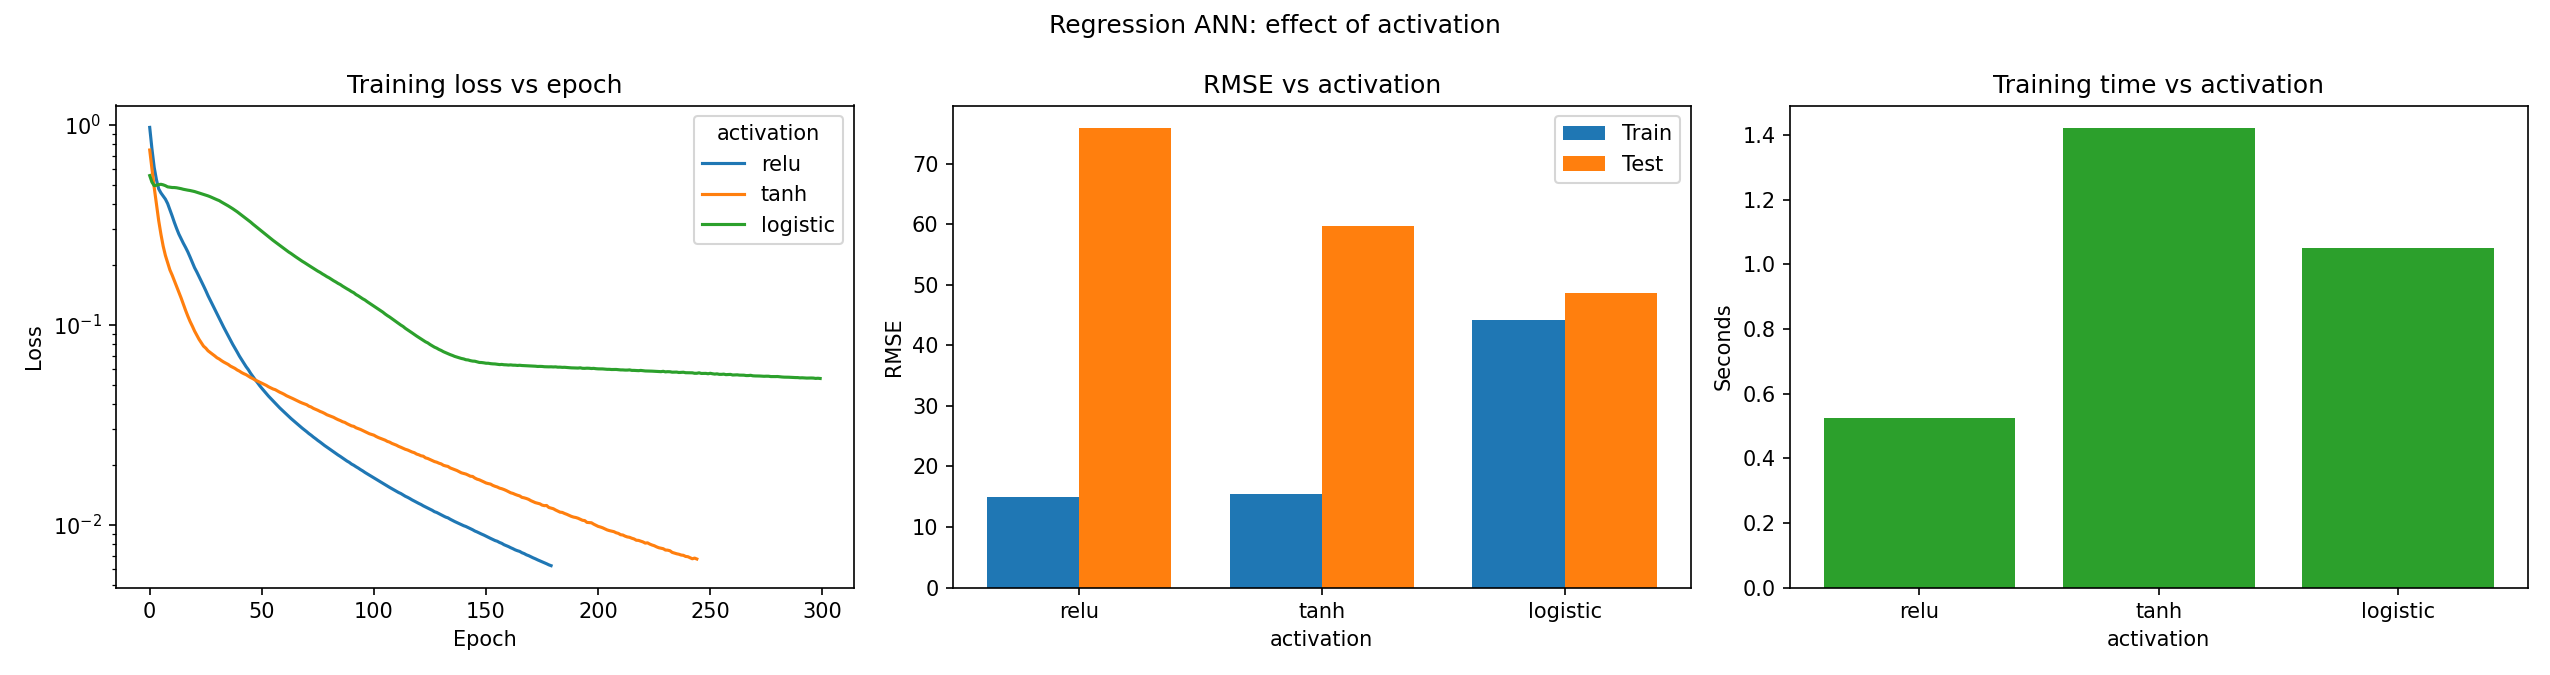

results/regression_heatmap_activation_lr.png


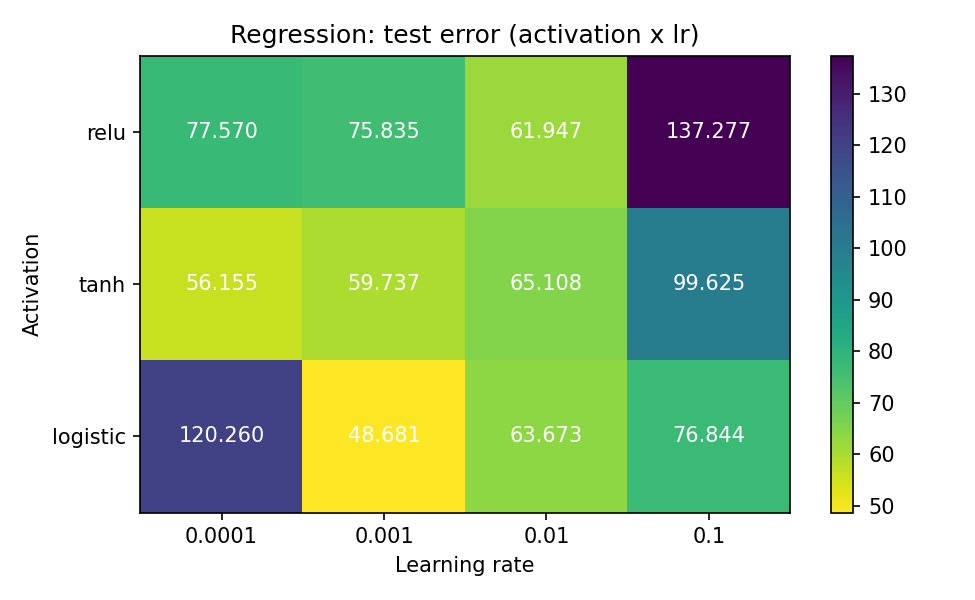

results/regression_hidden_layers.png


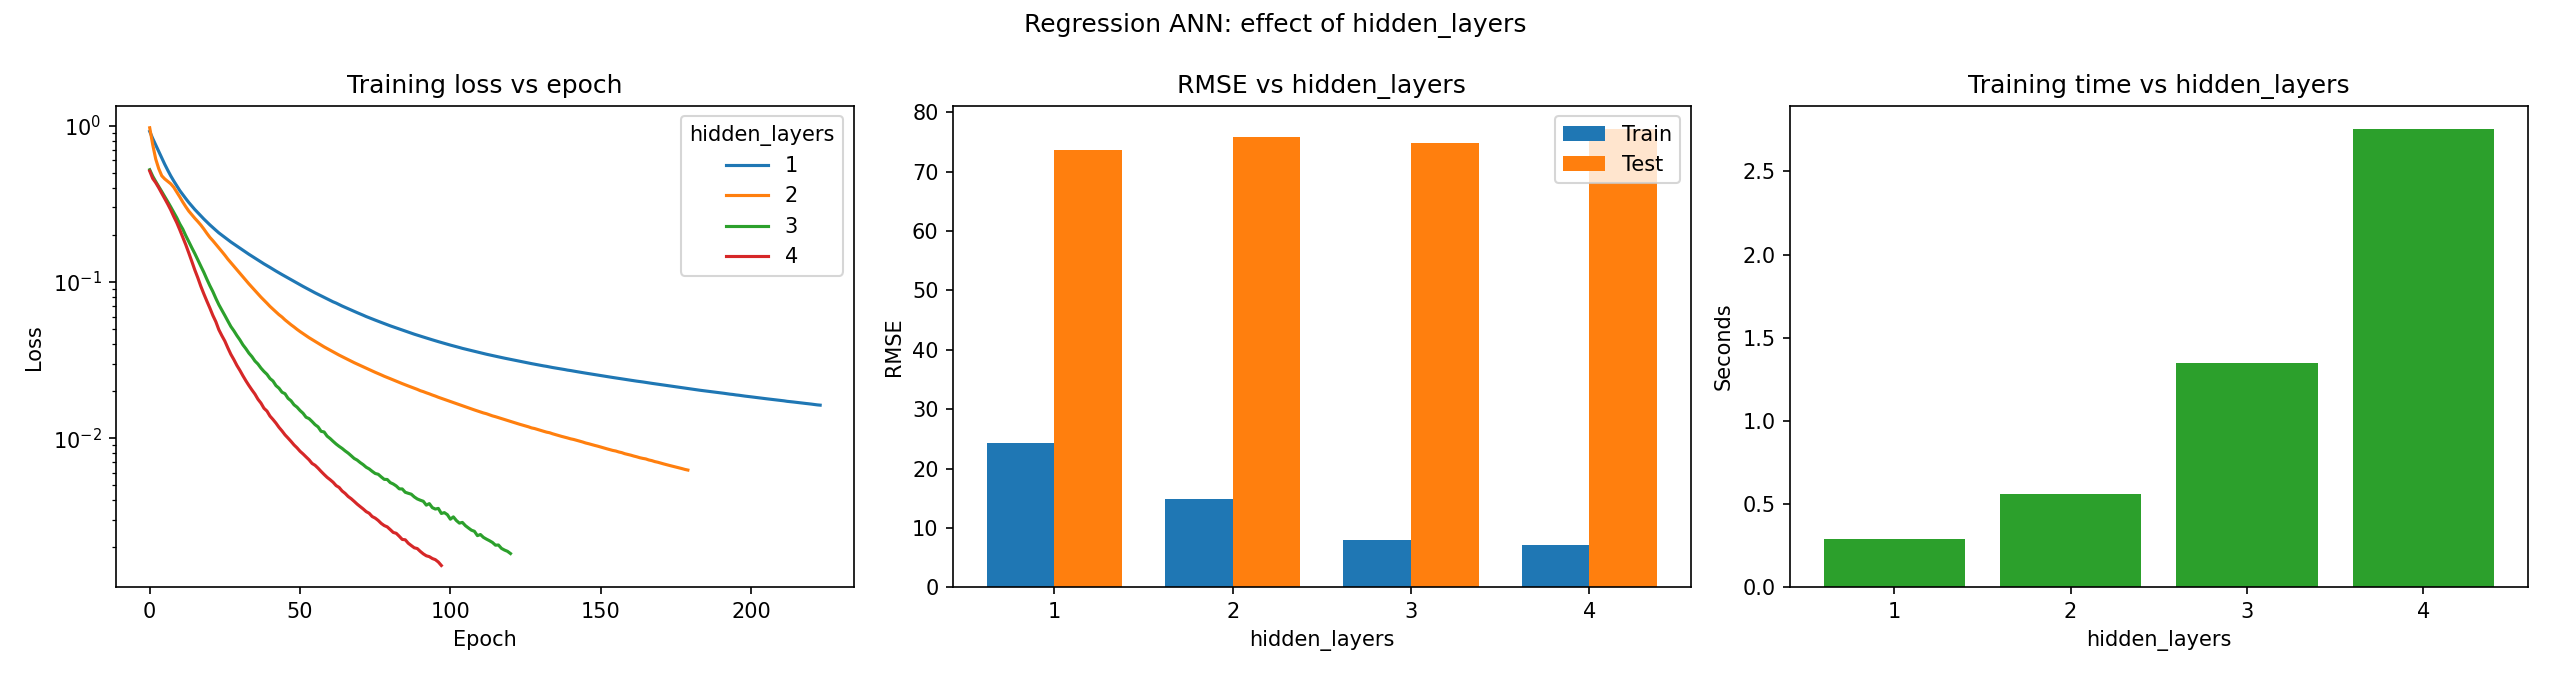

results/regression_learning_rate.png


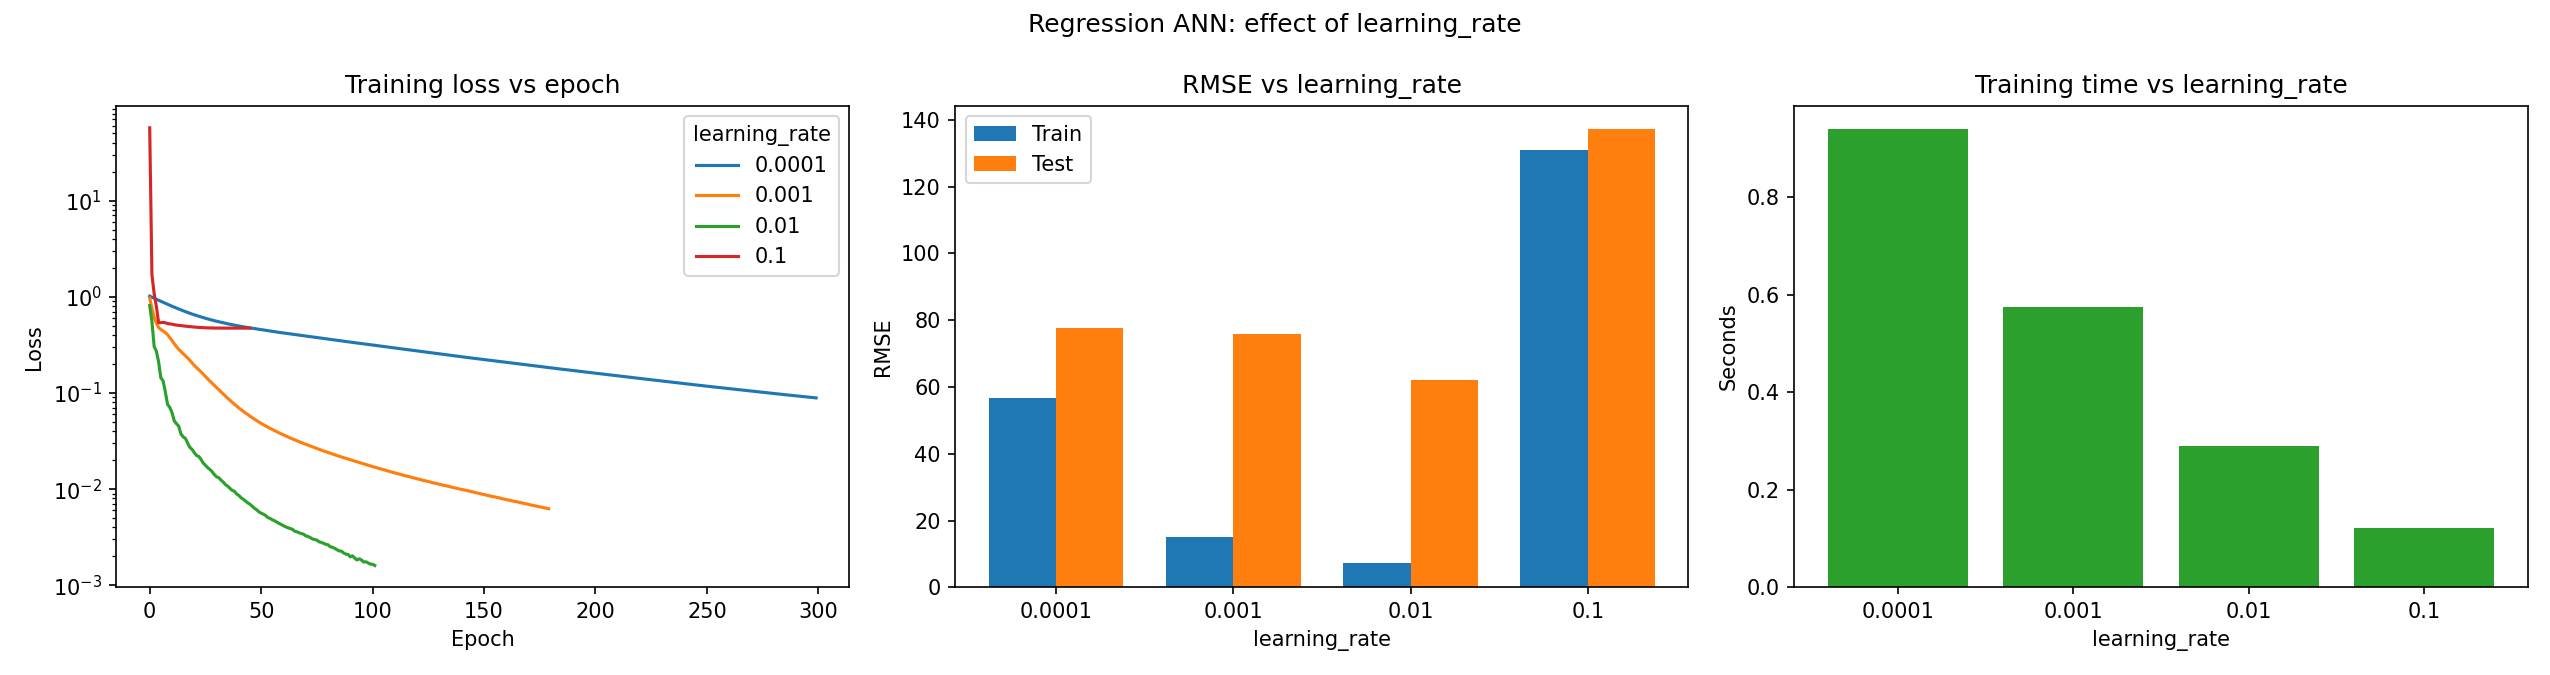

In [4]:
import glob
from IPython.display import Image, display
for f in sorted(glob.glob("results/*.png")):
    print(f)
    display(Image(f))

In [5]:
!zip -r results.zip results
from google.colab import files
files.download("results.zip")

  adding: results/ (stored 0%)
  adding: results/regression_learning_rate.png (deflated 14%)
  adding: results/classification_learning_rate.png (deflated 13%)
  adding: results/regression_heatmap_activation_lr.png (deflated 9%)
  adding: results/classification_heatmap_activation_lr.png (deflated 10%)
  adding: results/comparison_regression_vs_classification.png (deflated 8%)
  adding: results/classification_hidden_layers.png (deflated 14%)
  adding: results/classification_activation.png (deflated 14%)
  adding: results/regression_results.csv (deflated 53%)
  adding: results/classification_results.csv (deflated 60%)
  adding: results/regression_activation.png (deflated 12%)
  adding: results/regression_hidden_layers.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>